# CAREMap · 03 Michigan validation

Stage 6 of the [project plan](https://claude.ai/artifact/AYBNdGqtaB2AcdvZ3tQKrc).

**The question:** the national childcare measure is a stand-in. It counts childcare *workers* (Census business data) rather than licensed *slots*. Does it agree with real licensed capacity?

**The test:** Michigan publishes every licensed provider with its capacity (MiLEAP, State of Michigan map service). For Michigan's counties, compare:
- our measure: childcare workers per child under 5 (both withheld-data bounds), and our childcare score
- the real thing: licensed slots per child under 5

**Caveats to keep in mind**
- Licensed capacity covers all ages (0-12), not just under 5, so slots per young child is inflated where there's a lot of school-age care.
- License-exempt care (relatives, some programs) isn't in the licensing file, but some of it is in the Census counts.
- The licensing file is current (2025-26); the business data is 2023.
- Michigan has 83 counties, so this is one state's check, not proof for the whole country.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

scores = pd.read_csv(ROOT / "data/processed/county_scores_v1.csv", dtype={"GEOID": str})
join = pd.read_csv(ROOT / "data/processed/county_v1_join.csv", dtype={"GEOID": str})
lic = pd.read_csv(ROOT / "data/raw/mi_licensed_childcare_v2.csv", dtype={"GEOID": str})

mi = scores[scores["USPS"] == "MI"].merge(
    join[["GEOID", "mi_licensed_capacity", "mi_licensed_providers"]], on="GEOID", how="left")
print(f"Licensed providers: {len(lic):,}; total capacity: {pd.to_numeric(lic['Capacity'], errors='coerce').sum():,.0f}")
print(lic["FacilityType"].value_counts().to_string())
print(f"\nMichigan counties: {len(mi)}; scored: {(~mi['screened_out']).sum()}")

Licensed providers: 7,700; total capacity: 396,960
FacilityType
Center               4549
Family Home (1-6)    1771
Group Home (7-12)    1380

Michigan counties: 83; scored: 82


## 1. Build the two measures

In [2]:
m = mi[~mi["screened_out"]].copy()
m["slots_per_kid"] = m["mi_licensed_capacity"] / m["kids_under5"]
m["kids_per_slot"] = m["kids_under5"] / m["mi_licensed_capacity"]
m["workers_per_kid_low"] = m["workers_low"] / m["kids_under5"]
m["workers_per_kid_high"] = m["workers_high"] / m["kids_under5"]

print(f"Counties with 3+ young children per licensed slot (the classic 'desert' line): "
      f"{(m['kids_per_slot'] >= 3).sum()} of {len(m)}")
m[["slots_per_kid", "kids_per_slot", "workers_per_kid_low", "workers_per_kid_high", "childcare_score"]].describe().round(3)

Counties with 3+ young children per licensed slot (the classic 'desert' line): 3 of 82


,slots_per_kid,kids_per_slot,workers_per_kid_low,workers_per_kid_high,childcare_score
count,82.000,82.000,82.000,82.000,82.000
mean,0.660,1.667,0.056,0.063,59.494
std,0.183,0.653,0.023,0.022,21.481
min,0.174,0.892,0.000,0.025,10.034
25%,0.532,1.293,0.038,0.048,41.646
50%,0.637,1.570,0.057,0.064,61.760
75%,0.773,1.878,0.070,0.074,78.985
max,1.121,5.750,0.119,0.140,92.633


## 2. Do they agree?

Spearman rank correlation (does the proxy put counties in the same order as licensed capacity?).
- Workers per kid vs. slots per kid: we want a strong **positive** correlation.
- Childcare score vs. slots per kid: the score is high where supply is low, so we want a strong **negative** correlation.

Rough guide: |ρ| above 0.7 strong, 0.4-0.7 moderate, below 0.4 weak.

In [3]:
def rho(a, b, data):
    d = data[[a, b]].dropna()
    return d[a].rank().corr(d[b].rank()), len(d)

rows = []
for label, sub in [("All scored MI counties", m),
                   ("CBP published", m[~m["cbp_withheld_0to2"]]),
                   ("CBP withheld (0-2 businesses)", m[m["cbp_withheld_0to2"]]),
                   ("Metro", m[m["group"] == "Metro"]),
                   ("Nonmetro", m[m["group"] == "Nonmetro"])]:
    r_low, n = rho("workers_per_kid_low", "slots_per_kid", sub)
    r_high, _ = rho("workers_per_kid_high", "slots_per_kid", sub)
    r_score, _ = rho("childcare_score", "slots_per_kid", sub)
    rows.append({"subset": label, "counties": n, "workers/kid (low) vs slots/kid": round(r_low, 2),
                 "workers/kid (high) vs slots/kid": round(r_high, 2), "childcare score vs slots/kid": round(r_score, 2)})
agreement = pd.DataFrame(rows)
agreement

,subset,counties,workers/kid (low) vs slots/kid,workers/kid (high) vs slots/kid,childcare score vs slots/kid
0,All scored MI counties,82,0.62,0.38,-0.49
1,CBP published,70,0.50,0.50,-0.47
2,CBP withheld (0-2 businesses),12,0.22,0.15,-0.10
3,Metro,30,0.62,0.62,-0.62
4,Nonmetro,52,0.59,0.22,-0.45


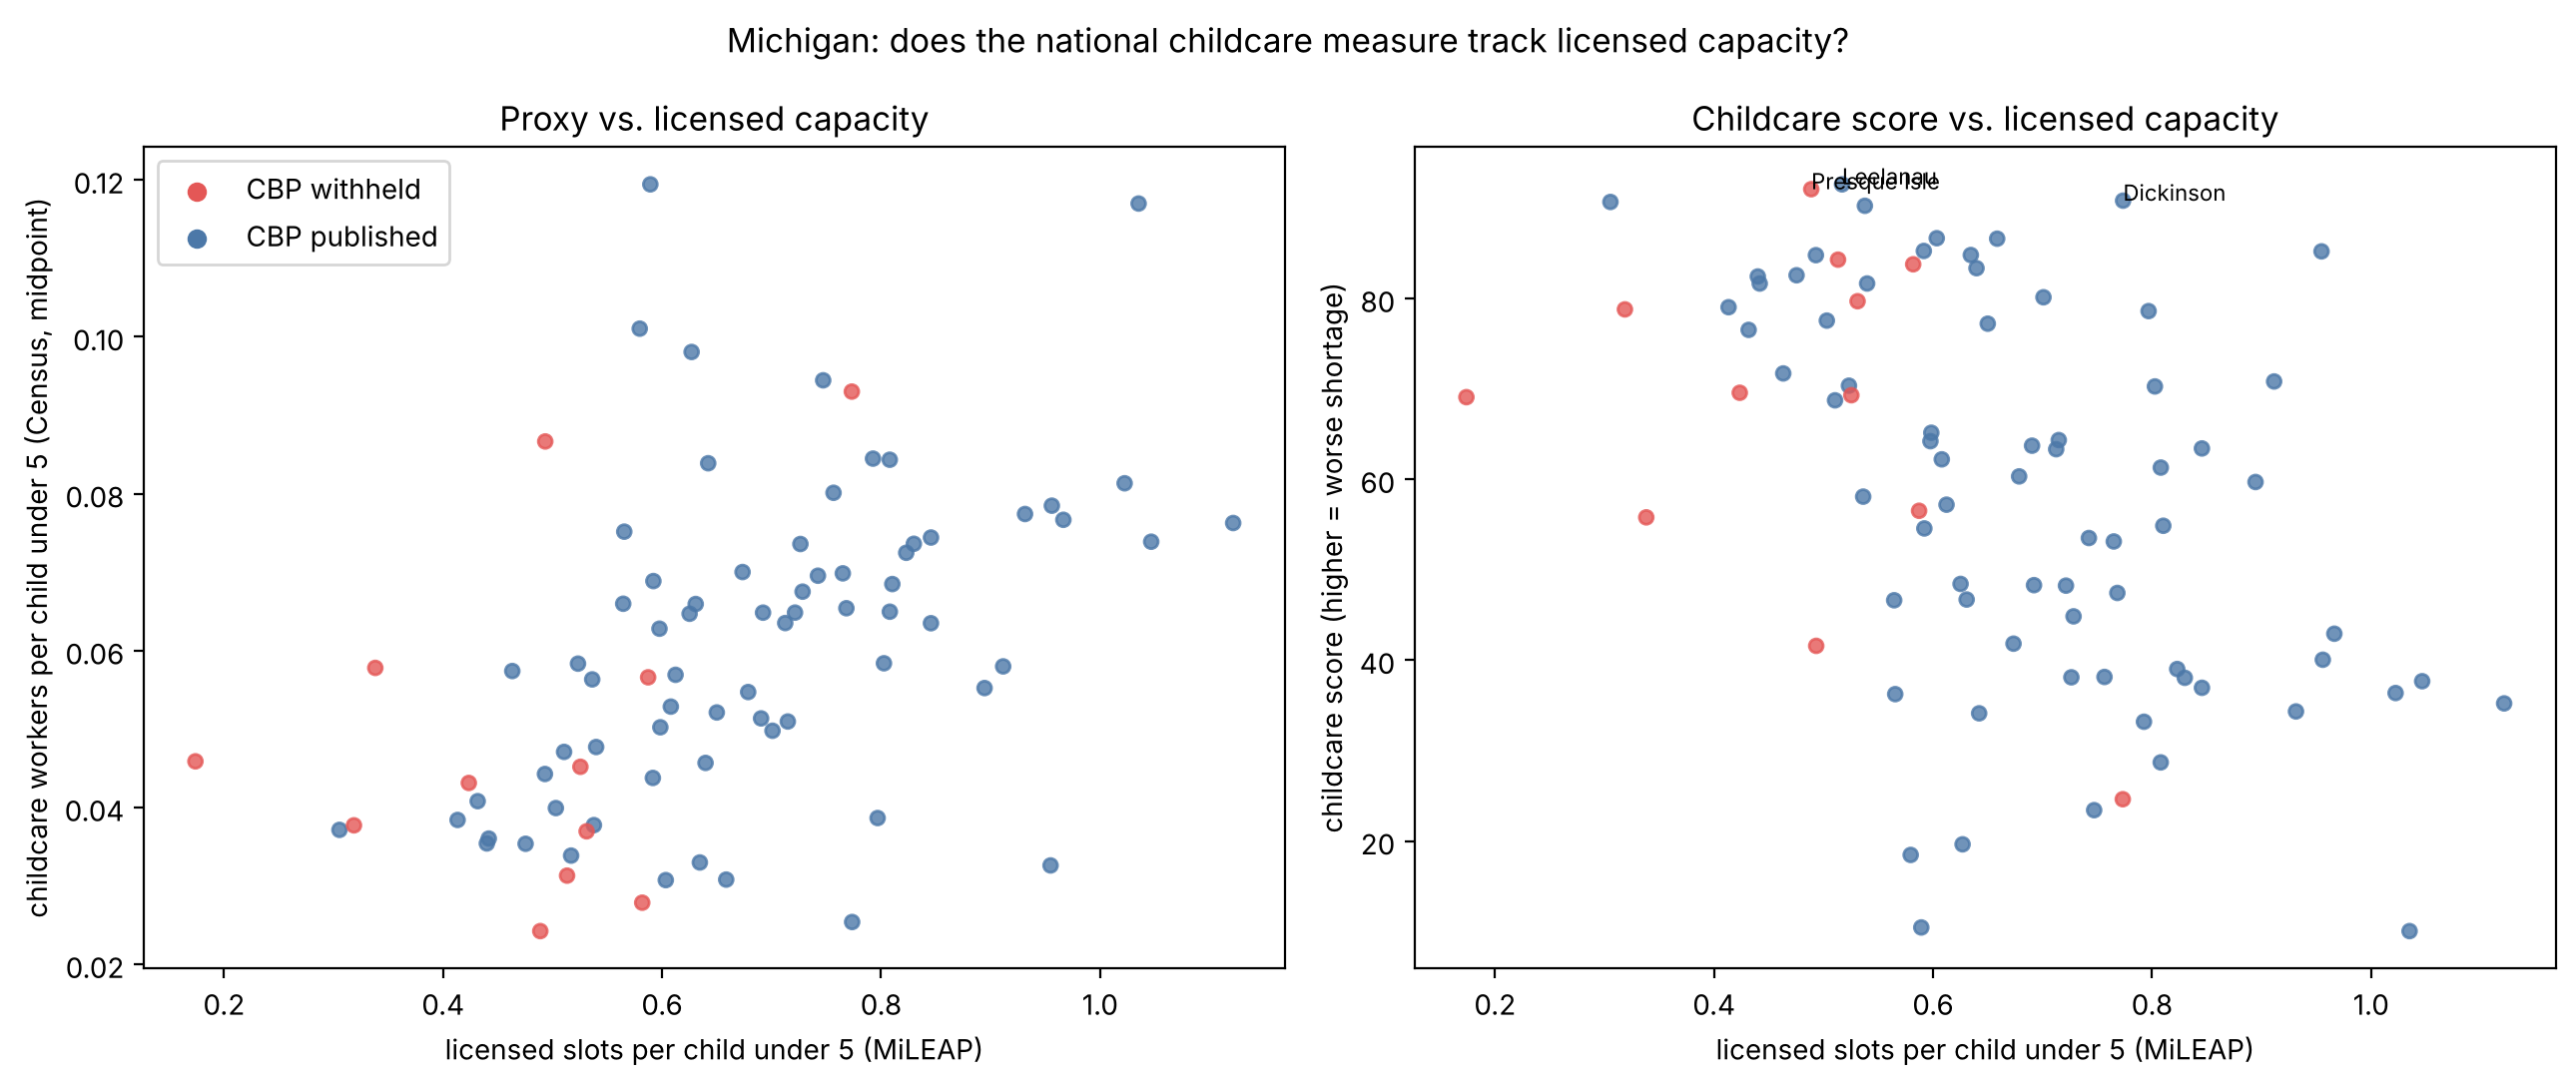

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
c = np.where(m["cbp_withheld_0to2"], "#E45756", "#4C78A8")
axes[0].scatter(m["slots_per_kid"], (m["workers_per_kid_low"] + m["workers_per_kid_high"]) / 2, c=c, s=25, alpha=0.8)
axes[0].set_xlabel("licensed slots per child under 5 (MiLEAP)")
axes[0].set_ylabel("childcare workers per child under 5 (Census, midpoint)")
axes[0].set_title("Proxy vs. licensed capacity")
axes[1].scatter(m["slots_per_kid"], m["childcare_score"], c=c, s=25, alpha=0.8)
axes[1].set_xlabel("licensed slots per child under 5 (MiLEAP)")
axes[1].set_ylabel("childcare score (higher = worse shortage)")
axes[1].set_title("Childcare score vs. licensed capacity")
for name, row in m.nlargest(3, "childcare_score").iterrows():
    axes[1].annotate(row["county_name"].replace(" County", ""), (row["slots_per_kid"], row["childcare_score"]), fontsize=8)
axes[0].scatter([], [], c="#E45756", label="CBP withheld"); axes[0].scatter([], [], c="#4C78A8", label="CBP published")
axes[0].legend()
fig.suptitle("Michigan: does the national childcare measure track licensed capacity?")
fig.tight_layout()
fig.savefig(FIG / "03_mi_validation.png", dpi=150)
plt.show()

## 3. Do the worst counties match?

What matters for the map is whether the counties we flag as the worst shortages are the ones with the least licensed capacity. Compare the bottom quarter on licensed slots per child with the top quarter on our childcare score.

In [5]:
q = max(1, int(round(len(m) * 0.25)))
worst_licensed = set(m.nsmallest(q, "slots_per_kid")["GEOID"])
worst_ours = set(m.nlargest(q, "childcare_score")["GEOID"])
overlap = worst_licensed & worst_ours
print(f"Worst quarter by licensed capacity: {q} counties")
print(f"Also in our worst quarter: {len(overlap)} ({len(overlap) / q:.0%}); chance alone would give about 25%")

m["licensed_worst_q"] = m["GEOID"].isin(worst_licensed)
m["our_worst_q"] = m["GEOID"].isin(worst_ours)
cols = ["county_name", "group", "kids_under5", "mi_licensed_capacity", "kids_per_slot", "childcare_score",
        "tier", "cbp_withheld_0to2"]
print("\nWhere they disagree:")
display(m[m["licensed_worst_q"] != m["our_worst_q"]].sort_values("kids_per_slot", ascending=False)[cols + ["licensed_worst_q", "our_worst_q"]].round(2))

Worst quarter by licensed capacity: 20 counties
Also in our worst quarter: 8 (40%); chance alone would give about 25%

Where they disagree:


,county_name,group,kids_under5,mi_licensed_capacity,kids_per_slot,childcare_score,tier,cbp_withheld_0to2,licensed_worst_q,our_worst_q
67,Oscoda County,Nonmetro,414,72.0,5.75,69.09,Low,True,True,False
35,Iron County,Nonmetro,477,152.0,3.14,78.80,Medium,True,True,False
0,Alcona County,Nonmetro,346,117.0,2.96,55.80,Low,True,True,False
11,Branch County,Nonmetro,2889,1194.0,2.42,79.05,Medium,False,True,False
47,Luce County,Nonmetro,255,108.0,2.36,69.58,Low,True,True,False
15,Cheboygan County,Nonmetro,980,423.0,2.32,76.54,Medium,False,True,False
73,St. Clair County,Metro,7752,3591.0,2.16,71.72,Medium,False,True,False
65,Ontonagon County,Nonmetro,150,74.0,2.03,41.59,Low,True,True,False
29,Hillsdale County,Nonmetro,2479,1247.0,1.99,77.56,Low,False,True,False
34,Iosco County,Nonmetro,1189,607.0,1.96,68.74,Low,False,True,False


## 4. Check the Michigan tiers against licensed capacity

In [6]:
m.groupby("tier")[["kids_per_slot", "slots_per_kid"]].median().round(2)

,kids_per_slot,slots_per_kid
tier,,
Low,1.46,0.68
Medium,1.77,0.56


In [7]:
out = m[["GEOID", "county_name", "group", "kids_under5", "mi_licensed_capacity", "mi_licensed_providers",
          "slots_per_kid", "kids_per_slot", "workers_per_kid_low", "workers_per_kid_high",
          "childcare_score", "tier", "cbp_withheld_0to2", "licensed_worst_q", "our_worst_q"]]
out.to_csv(ROOT / "data/processed/mi_validation.csv", index=False)
agreement.to_csv(ROOT / "data/processed/mi_validation_summary.csv", index=False)
print("Saved data/processed/mi_validation.csv and mi_validation_summary.csv")

Saved data/processed/mi_validation.csv and mi_validation_summary.csv


## What this means

Write the verdict here once you've read the numbers: does the proxy hold up in Michigan, and where does it fail?